# Coleta e Tratamento de Dados

## Objetivo
Definir uma fonte de dados, registrar ativo, período e frequência, carregar os preços, verificar datas ausentes, duplicatas e valores inválidos. Não sobrescrever os dados brutos.



## 2. Fundamentação teórica
Apresente os conceitos, hipóteses, equações e referências utilizadas.

## 3. Dados e metodologia
Descreva a origem dos dados, variáveis, período, frequência, tratamento e parâmetros. Registre decisões para permitir reprodução.

In [3]:
# TODO: importar as bibliotecas necessárias e implementar a análise.

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path



# 2. Coleta e Tratamento de Dados

## 2.1 Objetivo

Esta etapa tem como objetivo obter dados históricos do mercado financeiro, realizar sua validação e preparar uma base estruturada para as análises estatísticas posteriores.

Será utilizado o Yahoo Finance como fonte de dados, com acesso por meio da biblioteca Python yfinance.

O primeiro conjunto de dados será referente ao índice Ibovespa (^BVSP), utilizando observações históricas diárias.

Os dados originais serão armazenados na pasta data/raw, enquanto os dados tratados serão armazenados em data/processed.

A separação permite preservar os dados obtidos na fonte e manter a rastreabilidade das transformações realizadas.

## 4. Resultados
Apresente tabelas, gráficos e medidas relevantes, com títulos, unidades e legendas.

## 5. Interpretação
Explique o que os resultados mostram e o que não permitem concluir.

In [4]:

# Parâmetros da coleta
ticker = "^BVSP"
data_inicio = "2015-01-01"
data_fim = "2026-11-16"

# Identificar a raiz do projeto
raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Criar diretórios, caso não existam
pasta_raw = raiz_projeto / "data" / "raw"
pasta_processed = raiz_projeto / "data" / "processed"

pasta_raw.mkdir(parents=True, exist_ok=True)
pasta_processed.mkdir(parents=True, exist_ok=True)

# Download dos dados
dados_brutos = yf.download(
    ticker,
    start=data_inicio,
    end=data_fim,
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Verificar se a coleta retornou dados
if dados_brutos.empty:
    raise ValueError(
        "Nenhum dado foi retornado. Verifique o ticker e a conexão."
    )

# Ajustar colunas caso o yfinance retorne MultiIndex
if isinstance(dados_brutos.columns, pd.MultiIndex):
    dados_brutos.columns = dados_brutos.columns.get_level_values(0)

# Salvar os dados originais
arquivo_raw = pasta_raw / "ibovespa_historico.csv"
dados_brutos.to_csv(arquivo_raw)

print("Coleta concluída!")
print(f"Quantidade de registros: {len(dados_brutos)}")
print(f"Arquivo salvo em: {arquivo_raw}")


Coleta concluída!
Quantidade de registros: 2946
Arquivo salvo em: c:\Users\Mateus.RH\Desktop\Statistical-Physics-Financial-Markets-main\data\raw\ibovespa_historico.csv


In [5]:

# Visualizar primeiras observações
display(dados_brutos.head())

# Visualizar últimas observações
display(dados_brutos.tail())

# Estrutura e tipos das colunas
print("\nInformações da base:")
dados_brutos.info()

# Estatísticas descritivas
display(dados_brutos.describe())


Price,Close,High,Low,Open,Volume
Date,,,,,
2015-01-02,48512.0,50005.0,48345.0,50005.0,2882100
2015-01-05,47517.0,48512.0,47264.0,48512.0,3866100
2015-01-06,48001.0,48061.0,47338.0,47517.0,4559300
2015-01-07,49463.0,49882.0,48006.0,48006.0,4408800
2015-01-08,49943.0,50261.0,49017.0,49463.0,3621900


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-11-09,172236.0,172236.0,168499.0,168499.0,10102700
2026-11-10,171337.0,173272.0,170569.0,172238.0,10543700
2026-11-11,172060.0,172987.0,171335.0,171337.0,10542600
2026-11-12,171324.0,172060.0,169942.0,172060.0,13246300
2026-11-13,172458.0,172716.0,171132.0,171324.0,10691600



Informações da base:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2946 entries, 2015-01-02 to 2026-11-13
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2946 non-null   float64
 1   High    2946 non-null   float64
 2   Low     2946 non-null   float64
 3   Open    2946 non-null   float64
 4   Volume  2946 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 138.1 KB


Price,Close,High,Low,Open,Volume
count,2946.000000,2946.000000,2946.000000,2946.000000,2.946000e+03
mean,102571.468432,103428.550916,101678.580448,102531.577733,7.623256e+06
std,35741.417255,35944.409757,35535.610090,35732.037296,4.176398e+06
min,37497.000000,38031.000000,37046.000000,37501.000000,0.000000e+00
25%,74410.000000,75135.250000,73617.250000,74373.000000,3.849675e+06
50%,105140.500000,106014.000000,104109.000000,105074.000000,7.510250e+06
75%,124189.750000,124907.250000,123265.250000,124142.250000,1.055995e+07
max,209067.000000,209714.000000,206238.000000,209072.000000,4.123240e+07


In [6]:

# Criar uma cópia para preservar os dados brutos
dados_tratados = dados_brutos.copy()

# Ordenar os registros cronologicamente
dados_tratados = dados_tratados.sort_index()

# Remover datas duplicadas, mantendo o último registro
dados_tratados = dados_tratados[
    ~dados_tratados.index.duplicated(keep="last")
]

# Verificar valores ausentes
print("Valores ausentes:")
print(dados_tratados.isna().sum())

# Remover registros sem preço de fechamento
dados_tratados = dados_tratados.dropna(subset=["Close"])

# Garantir preços positivos
dados_tratados = dados_tratados[
    dados_tratados["Close"] > 0
]

# Verificação final
print("\nRegistros após tratamento:", len(dados_tratados))
print("Datas duplicadas:", dados_tratados.index.duplicated().sum())
print("Valores ausentes no fechamento:", dados_tratados["Close"].isna().sum())
print("Preços não positivos:", (dados_tratados["Close"] <= 0).sum())


Valores ausentes:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Registros após tratamento: 2946
Datas duplicadas: 0
Valores ausentes no fechamento: 0
Preços não positivos: 0


In [7]:

# Selecionar o preço de fechamento
base = dados_tratados[["Close"]].copy()

# Renomear coluna
base.rename(columns={"Close": "Preco_Fechamento"}, inplace=True)

# Calcular retornos simples
base["Retorno_Simples"] = base["Preco_Fechamento"].pct_change()

# Calcular retornos logarítmicos
base["Retorno_Log"] = np.log(
    base["Preco_Fechamento"] /
    base["Preco_Fechamento"].shift(1)
)

# Remover a primeira observação sem retorno
base = base.dropna()

# Verificar resultado
display(base.head())
display(base.tail())

print("\nDimensões da base tratada:", base.shape)


Price,Preco_Fechamento,Retorno_Simples,Retorno_Log
Date,,,
2015-01-05,47517.0,-0.020510,-0.020724
2015-01-06,48001.0,0.010186,0.010134
2015-01-07,49463.0,0.030458,0.030003
2015-01-08,49943.0,0.009704,0.009657
2015-01-09,48840.0,-0.022085,-0.022333


Price,Preco_Fechamento,Retorno_Simples,Retorno_Log
Date,,,
2026-11-09,172236.0,0.022178,0.021936
2026-11-10,171337.0,-0.005220,-0.005233
2026-11-11,172060.0,0.004220,0.004211
2026-11-12,171324.0,-0.004278,-0.004287
2026-11-13,172458.0,0.006619,0.006597



Dimensões da base tratada: (2945, 3)


In [8]:

arquivo_processed = (
    pasta_processed / "ibovespa_tratado.csv"
)

base.to_csv(
    arquivo_processed,
    index_label="Data"
)

print("Base processada salva com sucesso!")
print(arquivo_processed)


Base processada salva com sucesso!
c:\Users\Mateus.RH\Desktop\Statistical-Physics-Financial-Markets-main\data\processed\ibovespa_tratado.csv


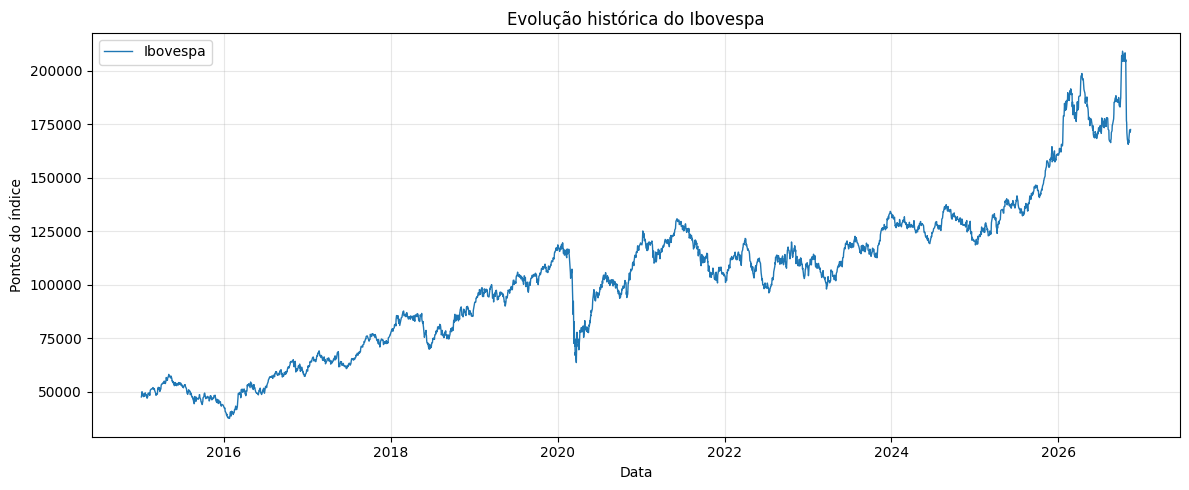

In [9]:

plt.figure(figsize=(12, 5))

plt.plot(
    base.index,
    base["Preco_Fechamento"],
    label="Ibovespa",
    linewidth=1
)

plt.title("Evolução histórica do Ibovespa")
plt.xlabel("Data")
plt.ylabel("Pontos do índice")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Validação e limitações
Verifique consistência, dados ausentes, sensibilidade aos parâmetros e limitações do método.

## 2.2 Procedimentos de Coleta e Tratamento

Os dados históricos foram obtidos por meio da biblioteca yfinance, utilizando informações disponibilizadas pelo Yahoo Finance.

Foi selecionado o índice Ibovespa (^BVSP), com frequência diária e período histórico iniciado em janeiro de 2015.

O tratamento contemplou:

- Ordenação cronológica das observações;
- Identificação e remoção de datas duplicadas;
- Verificação de valores ausentes;
- Exclusão de registros sem preço de fechamento;
- Verificação da positividade dos preços;
- Cálculo dos retornos simples e logarítmicos.

Os dados originais foram preservados na pasta data/raw, enquanto a base tratada foi armazenada em data/processed.

Essa organização permite manter a rastreabilidade das transformações e possibilita a reprodução das análises posteriores.

## Conclusão — Etapa 2: Coleta e tratamento de dados

A etapa de coleta e tratamento dos dados do Ibovespa foi concluída corretamente. Os dados históricos foram obtidos por meio da biblioteca `yfinance`, utilizando o Yahoo Finance como fonte, com frequência diária e período de análise de 2015 até novembro de 2026.

Durante o processo, foi realizada uma inspeção inicial da base para verificar sua estrutura, os tipos de dados e a consistência das informações. Em seguida, foram aplicados procedimentos de tratamento, incluindo a ordenação cronológica dos registros, a verificação e remoção de datas duplicadas, a identificação de valores ausentes e a exclusão de observações com preços de fechamento inválidos ou não positivos.

Após a limpeza, foram calculados os retornos simples e logarítmicos a partir dos preços de fechamento. Esses indicadores permitem analisar as variações percentuais do índice ao longo do tempo e constituem a base matemática para as próximas etapas do projeto.

Os dados foram organizados em dois conjuntos: os arquivos brutos, preservados para manter a fonte original, e os arquivos processados, preparados para as análises estatísticas posteriores. Essa separação contribui para a reprodutibilidade, a organização e a rastreabilidade do trabalho.

Conclui-se que a base de dados está estruturada e preparada para a etapa de análise exploratória. A validação dos registros e dos cálculos permite avançar para a investigação do comportamento dos retornos do Ibovespa, com foco em medidas estatísticas, distribuição de probabilidades, volatilidade, assimetria e curtose.

### Próxima etapa — Análise exploratória dos dados (EDA)

O próximo objetivo será investigar o comportamento histórico do Ibovespa e de seus retornos, procurando identificar:

1. Tendências e variações ao longo do tempo.
2. Comportamento dos retornos simples e logarítmicos.
3. Volatilidade e períodos de maior instabilidade.
4. Distribuição dos retornos e comparação com a distribuição normal.
5. Presença de assimetria e eventos extremos.